Overall avg temp: 26.55.c
Max temp recorded: 31.05.c
Min temp recorded: 22.61.c
these are the Daily Average statistics :         Date  Temperature   Humidity  Wind_speed
0  2026-11-02     24.00000  82.500000    0.765000
1  2026-11-03     26.54000  60.625000    1.512500
2  2026-11-04     26.37250  58.500000    1.610000
3  2026-11-05     26.78750  55.500000    2.321250
4  2026-11-06     26.76375  51.125000    2.480000
5  2026-11-07     27.04000  41.333333    2.488333


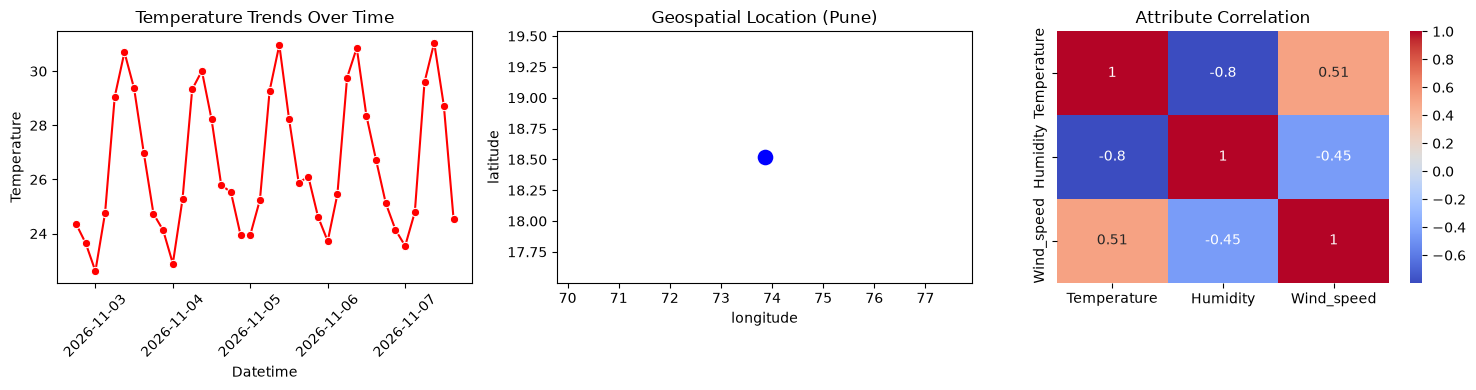

In [18]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

API_KEY = "720ae512822165421cb467f0aaced1b8"
CITY = "Pune"
url = f"http://api.openweathermap.org/data/2.5/forecast?q={CITY}&appid={API_KEY}&units=metric"

response = requests.get(url)
weather_list = []

if response.status_code == 200:
    data = response.json()

    for item in data['list']:
        weather_list.append({
            'Datetime' : item['dt_txt'],
            'Temperature' : item['main']['temp'],
            'Humidity' : item['main']['humidity'],
            'Wind_speed' : item['wind']['speed'],
            'Lat' : data['city']['coord']['lat'],
            'Lon' : data['city']['coord']['lon']
        })
else : 
    print("API failed!, Using mock data for exam safety.")

    weather_list = [
        {'Datetime':'2023-10-01 12:00:00', 'Temperature':28, 'Humidity':60, 'Wind_speed':5, 'Lat':18.52, 'Lon':73.85},
        {'Datetime':'2023-10-01 12:00:00', 'Temperature':28, 'Humidity':60, 'Wind_speed':5, 'Lat':18.52, 'Lon':73.85},
        {'Datetime':'2023-10-01 12:00:00', 'Temperature':28, 'Humidity':60, 'Wind_speed':5, 'Lat':18.52, 'Lon':73.85}
    ]

df = pd.DataFrame(weather_list)
df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.dropna()

print(f"Overall avg temp: {df['Temperature'].mean():.2f}.c")
print(f"Max temp recorded: {df['Temperature'].max():.2f}.c")
print(f"Min temp recorded: {df['Temperature'].min():.2f}.c")

df['Date'] = df['Datetime'].dt.date
daily_stats = df.groupby('Date')[['Temperature', 'Humidity', 'Wind_speed']].mean().reset_index()
print(f"these are the Daily Average statistics :{daily_stats}")

plt.figure(figsize = (15,4))

plt.subplot(1,3,1)
sns.lineplot(x = 'Datetime', y = 'Temperature', data = df, color='red', marker='o')
plt.xticks(rotation=45)
plt.title('Temperature Trends Over Time')

plt.subplot(1,3,2)
sns.scatterplot(x='Lon', y='Lat', data=df, color='blue', s=150)
plt.title(f'Geospatial Location ({CITY})')
plt.xlabel('longitude')
plt.ylabel('latitude')

plt.subplot(1,3,3)
sns.heatmap(df[['Temperature', 'Humidity', 'Wind_speed']].corr(), annot=True, cmap='coolwarm')
plt.title('Attribute Correlation')

plt.tight_layout()
plt.show()